# 01. Срок доставки для пары продавец–город

**Задача:** перед началом дня D спрогнозировать количество дней **от подтверждения оплаты до доставки** для каждой пары `seller_id × city_id`. Одна пара получает один прогноз на весь день; при оформлении заказа срок читается из готовой таблицы.

Обучение использует отдельные доставленные заказы как наблюдения распределения срока для пары на дату покупки. Признаки одинаковы у всех заказов одной пары в один день. Вес, цена, конкретный адрес, способ оплаты и другие свойства будущего заказа не используются.

Ноутбук включает EDA, признаки, константные и исторические бейзлайны, сравнение CatBoost на validation, фиксированную итоговую оценку, p50/p90 и пример ночного расчёта новых пар. Стандартный запуск занимает несколько минут на CPU.

In [1]:
from pathlib import Path
import sys, json, time, platform, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from catboost import CatBoostRegressor
import catboost, sklearn
from sklearn.metrics import mean_absolute_error, median_absolute_error, mean_squared_error, mean_pinball_loss
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'marts' / 'store.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from marts import MartStore
from marts.delivery_features import KEYS, make_delivery_features
from marts.delivery_batch import DeliveryModel, LocalPairFeatures

threadpool_limits(limits=4)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .22})
pd.set_option('display.max_columns', 16)
SEED = 42
REPORT = ROOT / 'reports' / 'delivery_eta'
MODEL_DIR = ROOT / 'models' / 'delivery_eta'
REPORT.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
def show_figure(name):
    plt.gcf().savefig(REPORT / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()

store = MartStore(ROOT / 'marts' / 'data')
task = store.task('delivery')
df = task.frame.sort_values(['forecast_date', 'seller_id', 'city_id', 'order_id']).reset_index(drop=True)
BASE_FEATURES = task.contract['features']
TARGET = 'delivery_days_from_approval'
DEV_AS_OF = pd.Timestamp('2018-03-01')
VALID_END = pd.Timestamp('2018-04-15')
FIT_AS_OF = pd.Timestamp('2018-06-01')
TEST_END = pd.Timestamp(store.manifest['parameters']['train_to'])
print('Версии:', {'python': platform.python_version(), 'pandas': pd.__version__, 'catboost': catboost.__version__, 'sklearn': sklearn.__version__})
print('Данные:', df.shape, '| пар:', df[KEYS[:2]].drop_duplicates().shape[0], '| пар-дней:', df[KEYS].drop_duplicates().shape[0])
print('Покупки:', df.forecast_date.min(), '—', df.forecast_date.max())

Версии: {'python': '3.12.14', 'pandas': '2.2.3', 'catboost': '1.2.10', 'sklearn': '1.9.1'}
Данные: (91267, 75) | пар: 56433 | пар-дней: 89273
Покупки: 2017-01-05 00:00:00 — 2018-08-14 00:00:00


## 1. Контракт и отбор наблюдений

Таргет измеряется в дробных днях: `(delivered_ts − approved_ts) / 86400`. Дата признаков — начало дня покупки. Не включаем заказы с несколькими продавцами: дата вручения общая, отдельные посылки не размечены. Оставляем положительные известные сроки и непротиворечивые полные этапы доставки. Длинные положительные сроки сохраняются.

Итог относится к доставленным одно-продавцовым заказам с корректными датами. Отмены и незавершённые доставки в регрессии не размечены; это ограничение выборки, а не нулевой срок.

In [2]:
lifecycle = store.read('fct_order_delivery')
order_features = store.read('fct_order_features')[['order_id', 'n_sellers']]
audit = lifecycle.merge(order_features, on='order_id', how='left', validate='one_to_one')
start = pd.Timestamp(store.manifest['parameters']['train_from'])
in_window = audit.purchase_ts.ge(start) & audit.purchase_ts.lt(TEST_END)
funnel = pd.DataFrame([
    ('Все заказы', len(audit)),
    ('Покупки в окне обучения', int(in_window.sum())),
    ('В окне, есть доставка и позиции', int((in_window & audit.is_delivered & audit.has_items).sum())),
    ('Корректные этапы и положительный таргет', int(audit.is_valid_for_training.sum())),
    ('Один продавец: итоговый датасет', len(df)),
], columns=['step', 'orders'])
display(funnel)
assert df.order_id.is_unique
assert df[TARGET].gt(0).all()
assert df.forecast_date.equals(df.purchase_ts.dt.normalize())
assert len(df[KEYS + BASE_FEATURES].drop_duplicates()) == len(df[KEYS].drop_duplicates())
forbidden = {'order_id', 'approved_ts', 'carrier_ts', 'delivered_ts', 'approval_hours',
             'handling_days', 'transit_days', 'main_payment_type', 'olist_estimate_days',
             'label_available_ts', 'order_status', TARGET}
assert not set(BASE_FEATURES) & forbidden
print('Признаки зависят только от продавца, города и дня; будущие события исключены из X.')
print('Последняя дата событий:', store.manifest['parameters']['snapshot_ts'])

,step,orders
0,Все заказы,99441
1,Покупки в окне обучения,96624
2,"В окне, есть доставка и позиции",93789
3,Корректные этапы и положительный таргет,92442
4,Один продавец: итоговый датасет,91267


Признаки зависят только от продавца, города и дня; будущие события исключены из X.
Последняя дата событий: 2018-10-29 12:27:35


## 2. Временной эксперимент

- **Разработка:** покупки до 1 марта 2018; метки только доставок, известных до этого дня.
- **Validation:** покупки 1 марта – 14 апреля; для выбора модели к 1 июня доступны только доставки до 1 июня. Промежуток после 14 апреля даёт меткам время созреть.
- **Итоговая модель:** переобучение с фиксированными параметрами на всех покупках и доставках, известных до 1 июня.
- **Test:** покупки 1 июня – 14 августа, метки из полной выгрузки. Test не используется для выбора признаков, параметров, числа деревьев или калибровки.

Исторические признаки на test обновляются ежедневно по событиям до D. Это соответствует ночному расчёту с фиксированной моделью. Саму модель внутри test не переобучаем. Случайного разбиения нет.

In [3]:
dev_cohort = df[df.forecast_date.lt(DEV_AS_OF)]
train = dev_cohort[dev_cohort.label_available_ts.lt(DEV_AS_OF)].copy()
valid_cohort = df[df.forecast_date.ge(DEV_AS_OF) & df.forecast_date.lt(VALID_END)]
valid = valid_cohort[valid_cohort.label_available_ts.lt(FIT_AS_OF)].copy()
fit_cohort = df[df.forecast_date.lt(FIT_AS_OF)]
fit = fit_cohort[fit_cohort.label_available_ts.lt(FIT_AS_OF)].copy()
test = df[df.forecast_date.ge(FIT_AS_OF) & df.forecast_date.lt(TEST_END)].copy()
assert train.label_available_ts.max() < DEV_AS_OF
assert valid.label_available_ts.max() < FIT_AS_OF
assert fit.label_available_ts.max() < FIT_AS_OF
assert not set(fit.order_id) & set(test.order_id)
assert not set(train[KEYS].itertuples(index=False, name=None)) & set(valid[KEYS].itertuples(index=False, name=None))
split_summary = pd.DataFrame([
    {'part': name, 'orders': len(frame), 'pair_days': len(frame[KEYS].drop_duplicates()),
     'from': frame.forecast_date.min(), 'to': frame.forecast_date.max(),
     'unavailable_labels_excluded': total - len(frame)}
    for name, frame, total in [('train', train, len(dev_cohort)), ('valid', valid, len(valid_cohort)),
                               ('final_fit', fit, len(fit_cohort)), ('test', test, len(test))]
])
display(split_summary)
split_summary.to_csv(REPORT / 'splits.csv', index=False)
print('Validation исключает ещё не известные к 1 июня метки:', len(valid_cohort) - len(valid))

,part,orders,pair_days,from,to,unavailable_labels_excluded
0,train,52639,51512,2017-01-05,2018-02-27,3648
1,valid,9895,9680,2018-03-01,2018-04-14,26
2,final_fit,73696,72024,2017-01-05,2018-05-29,2376
3,test,15195,14907,2018-06-01,2018-08-14,0


Validation исключает ещё не известные к 1 июня метки: 26


## 3. EDA на train

Распределение и зависимости изучаем на train. Для истории проверяем долю холодного старта, расстояния, географию, сезонность и пропуски. Квантили хвоста помогают отличить шум доставки от аномалий; произвольного отсечения по 30/60 дням здесь нет.

,days
count,52639.000000
mean,12.513199
std,8.998911
min,0.526065
1%,1.716403
10%,4.483157
50%,10.683785
75%,15.533293
90%,22.098694
95%,27.682858


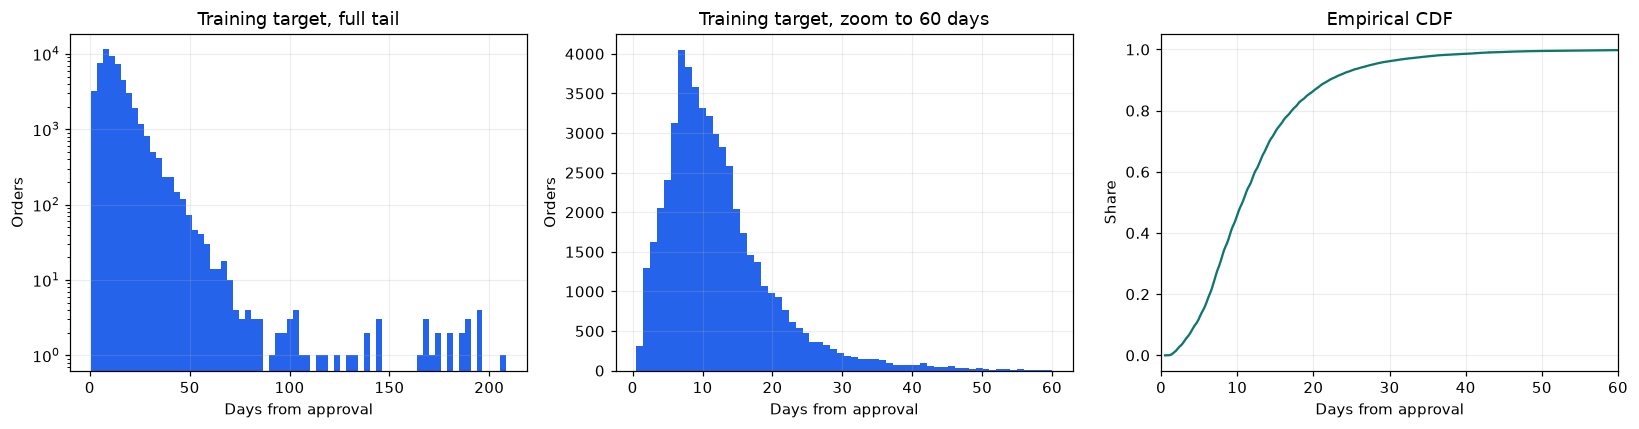

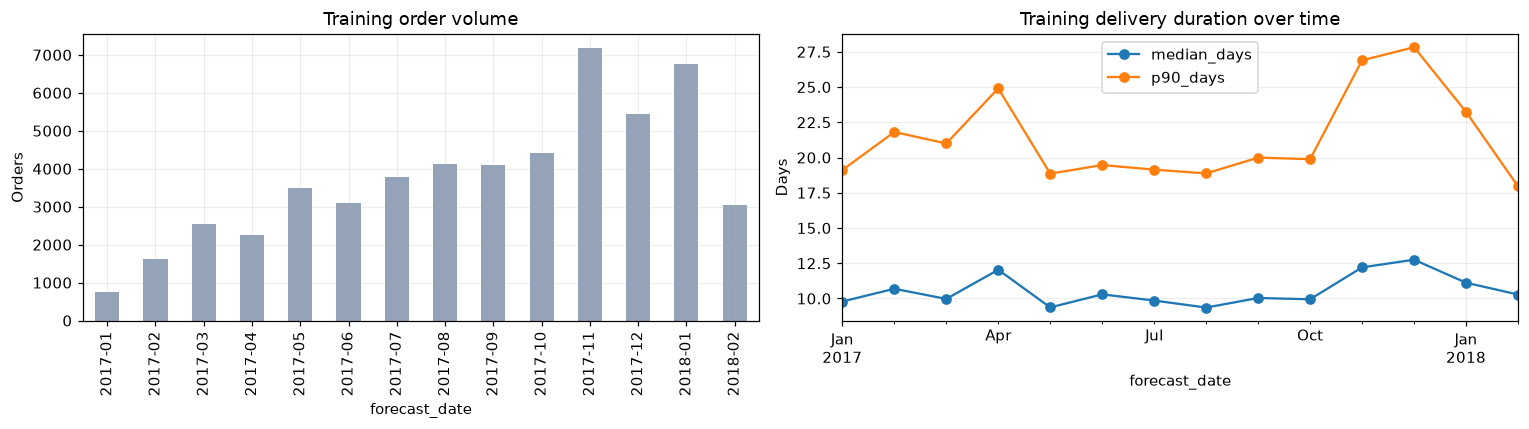

,orders,median_days,p90_days
forecast_date,,,
2017-07,3788,9.855307,19.140837
2017-08,4134,9.356152,18.870226
2017-09,4093,10.035926,19.994773
2017-10,4414,9.945619,19.881318
2017-11,7186,12.207130,26.891997
2017-12,5438,12.751551,27.825825
2018-01,6765,11.118796,23.240345
2018-02,3042,10.281904,17.953885


In [4]:
target_summary = train[TARGET].describe(percentiles=[.01, .1, .5, .75, .9, .95, .99]).to_frame('days')
display(target_summary)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(train[TARGET], bins=70, color='#2563eb')
axes[0].set(title='Training target, full tail', xlabel='Days from approval', ylabel='Orders', yscale='log')
axes[1].hist(train.loc[train[TARGET].le(60), TARGET], bins=60, color='#2563eb')
axes[1].set(title='Training target, zoom to 60 days', xlabel='Days from approval', ylabel='Orders')
v = np.sort(train[TARGET]); axes[2].plot(v, np.arange(1, len(v)+1)/len(v), color='#0f766e')
axes[2].set(title='Empirical CDF', xlabel='Days from approval', ylabel='Share', xlim=(0, 60))
plt.tight_layout(); show_figure('01_target_distribution')

monthly = train.groupby(train.forecast_date.dt.to_period('M')).agg(orders=('order_id','size'), median_days=(TARGET,'median'), p90_days=(TARGET,lambda s:s.quantile(.9)))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly.orders.plot.bar(ax=axes[0], color='#94a3b8'); axes[0].set(title='Training order volume', ylabel='Orders')
monthly[['median_days','p90_days']].plot(ax=axes[1], marker='o'); axes[1].set(title='Training delivery duration over time', ylabel='Days')
plt.tight_layout(); show_figure('02_training_time_trend')
display(monthly.tail(8))

,orders,share
pair_n_delivered,,
no pair history,35419,0.672866
1–4 deliveries,10282,0.195330
5+ deliveries,6938,0.131803


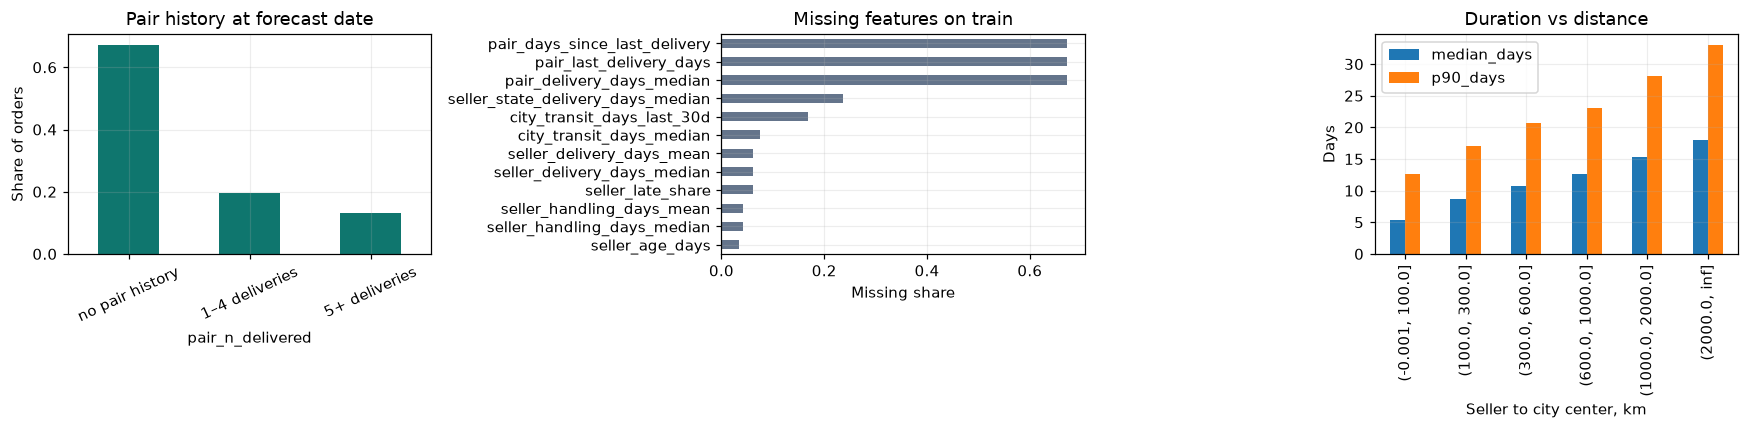

,orders,median_days,p90_days
distance_bucket,,,
"(-0.001, 100.0]",9232,5.301447,12.557137
"(100.0, 300.0]",7017,8.650579,17.112956
"(300.0, 600.0]",17721,10.710000,20.653380
"(600.0, 1000.0]",10097,12.672442,23.072308
"(1000.0, 2000.0]",5492,15.283061,28.192265
"(2000.0, inf]",3080,17.986655,33.071514


,size,median,mean
route,,,
SP-SP,16028,6.919693,8.160966
SP-RJ,4663,12.724398,15.305229
SP-MG,4230,10.735677,12.002234
SP-RS,2009,13.855278,16.071389
SP-PR,1715,11.379375,12.844808
MG-SP,1561,9.725150,11.065072
PR-SP,1518,9.810330,11.171542
SP-SC,1304,14.292992,16.076024
SP-BA,1213,16.869109,18.952203


Train: new seller share: 0.0617
Train: targets longer than 60 days: 115


In [5]:
coverage = pd.cut(train.pair_n_delivered, bins=[-1,0,4,np.inf], labels=['no pair history','1–4 deliveries','5+ deliveries'])
coverage_table = coverage.value_counts(sort=False).rename('orders').to_frame()
coverage_table['share'] = coverage_table.orders / len(train)
display(coverage_table)
missing = train[BASE_FEATURES].isna().mean().sort_values(ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
coverage_table['share'].plot.bar(ax=axes[0], color='#0f766e'); axes[0].set(title='Pair history at forecast date', ylabel='Share of orders'); axes[0].tick_params(axis='x',rotation=25)
missing.head(12).sort_values().plot.barh(ax=axes[1], color='#64748b'); axes[1].set(title='Missing features on train', xlabel='Missing share')
dist = train.assign(distance_bucket=pd.cut(train.distance_km, [0,100,300,600,1000,2000,np.inf], include_lowest=True))
distance_stats = dist.groupby('distance_bucket', observed=True)[TARGET].agg(['size','median',lambda s:s.quantile(.9)])
distance_stats.columns = ['orders','median_days','p90_days']
distance_stats[['median_days','p90_days']].plot.bar(ax=axes[2]); axes[2].set(title='Duration vs distance', xlabel='Seller to city center, km', ylabel='Days')
plt.tight_layout(); show_figure('03_history_missing_distance')
display(distance_stats)
route_stats = train.assign(route=train.seller_state+'-'+train.customer_state).groupby('route')[TARGET].agg(['size','median','mean']).sort_values('size', ascending=False).head(12)
display(route_stats)
print('Train: new seller share:', round(train.seller_n_delivered.eq(0).mean(),4))
print('Train: targets longer than 60 days:', int(train[TARGET].gt(60).sum()))

## 4. Feature engineering

Базовые 61 признак уже включают историю продавца, города, маршрута, пары и календаря. Дополнительно создаём:

- логарифмы расстояний, размеров истории и очереди продавца;
- флаги отсутствия истории и вес надёжности пары `n/(n+10)`;
- отношение текущей загрузки к месячной и очередь относительно недельного объёма;
- сумму подготовки продавцом и транзита по маршруту/городу;
- отклонения истории пары от продавца/штата и свежих сроков маршрута от общей истории;
- циклический календарь и время от начала периода.

Преобразование детерминировано и общее с пакетным прогнозом. Отдельно проверяем вариант с категориальными ID продавца и города. Все статистики целевой переменной уже посчитаны point-in-time в витрине; на полном датасете их заново не считаем. CatBoost обрабатывает числовые пропуски и категории.

In [6]:
X_demo, cat_demo = make_delivery_features(train, BASE_FEATURES, engineered=True, use_ids=False)
assert len(X_demo.drop_duplicates()) <= len(train[KEYS].drop_duplicates())
assert not set(X_demo) & forbidden
feature_catalog = pd.DataFrame({'feature': X_demo.columns,
                                'group': ['base' if c in BASE_FEATURES else 'engineered' for c in X_demo],
                                'categorical': [c in cat_demo for c in X_demo]})
display(feature_catalog[feature_catalog.group.eq('engineered')])
feature_catalog.to_csv(REPORT / 'feature_catalog.csv', index=False)
print('База:', len(BASE_FEATURES), '| с feature engineering:', X_demo.shape[1])

,feature,group,categorical
61,route_state,engineered,True
62,dow_sin,engineered,False
63,dow_cos,engineered,False
64,month_sin,engineered,False
65,month_cos,engineered,False
66,days_since_2017,engineered,False
67,log1p_distance_km,engineered,False
68,log1p_n_zip_prefixes,engineered,False
69,log1p_pair_n_delivered,engineered,False
70,log1p_seller_n_delivered,engineered,False


База: 61 | с feature engineering: 92


## 5. Бейзлайны и сравнение на validation

Главная метрика — **MAE в днях**. Для неё естественный константный бейзлайн — медиана; среднее также сохраняем для сравнения. Исторические бейзлайны доступны для новых заказов пары без знания состава заказа.

`pair_prior` — сглаженное среднее пары с иерархическим fallback. `handling + route` — сумма подготовки продавцом и времени транзита по маршруту. В варианте residual бустинг учит поправку к `pair_prior` вместо полного срока.

Оценка взвешена по заказам: частые направления имеют больший бизнес-вес. Дополнительно считаем MAE с равным весом каждого паро-дня. Обещание Olist здесь не используется как признак или основной бейзлайн: оно относится к отдельному заказу, а ночной прогноз должен работать до появления заказа.

In [7]:
def metrics(y, pred, frame):
    y = np.asarray(y, dtype=float); pred = np.asarray(pred, dtype=float)
    err = pred - y; absolute = np.abs(err)
    grouped = frame[KEYS].copy(); grouped['absolute_error'] = absolute
    return {'MAE': float(absolute.mean()), 'RMSE': float(np.sqrt(mean_squared_error(y, pred))),
            'MedianAE': float(np.median(absolute)), 'P90_AE': float(np.quantile(absolute,.9)),
            'Bias_pred_minus_actual': float(err.mean()), 'Within_3d': float((absolute<=3).mean()),
            'Within_5d': float((absolute<=5).mean()),
            'Pair_day_macro_MAE': float(grouped.groupby(KEYS).absolute_error.mean().mean())}

def baseline_predictions(frame, reference):
    return {'global_mean': np.repeat(reference[TARGET].mean(),len(frame)),
            'global_median': np.repeat(reference[TARGET].median(),len(frame)),
            'pair_prior': frame.pair_delivery_days_smoothed.to_numpy(),
            'handling_plus_route': (frame.seller_handling_days_smoothed+frame.route_transit_days_smoothed).to_numpy()}

valid_predictions = baseline_predictions(valid, train)
valid_rows = [{'model': name, **metrics(valid[TARGET], pred, valid)} for name,pred in valid_predictions.items()]
configs = [
    {'name':'catboost_base','engineered':False,'use_ids':False,'residual':False,'depth':6},
    {'name':'catboost_features','engineered':True,'use_ids':False,'residual':False,'depth':6},
    {'name':'catboost_residual','engineered':True,'use_ids':False,'residual':True,'depth':6},
    {'name':'catboost_residual_ids','engineered':True,'use_ids':True,'residual':True,'depth':6},
]
experiments = {}; y_train = train[TARGET].to_numpy(); y_valid = valid[TARGET].to_numpy()
for config in configs:
    xtr, cats = make_delivery_features(train, BASE_FEATURES, engineered=config['engineered'], use_ids=config['use_ids'])
    xva, _ = make_delivery_features(valid, BASE_FEATURES, engineered=config['engineered'], use_ids=config['use_ids'])
    offset_tr = train.pair_delivery_days_smoothed.to_numpy() if config['residual'] else np.zeros(len(train))
    offset_va = valid.pair_delivery_days_smoothed.to_numpy() if config['residual'] else np.zeros(len(valid))
    model = CatBoostRegressor(loss_function='MAE', iterations=1000, depth=config['depth'], learning_rate=.04,
                             random_seed=SEED, thread_count=4, allow_writing_files=False, verbose=False)
    started = time.time()
    model.fit(xtr, y_train-offset_tr, cat_features=cats, eval_set=(xva,y_valid-offset_va), early_stopping_rounds=100)
    pred = np.maximum(0,model.predict(xva)+offset_va)
    valid_predictions[config['name']] = pred
    experiments[config['name']] = {'model':model,'config':config,'iterations':model.tree_count_,
                                  'features':list(xtr),'categorical':cats}
    valid_rows.append({'model':config['name'],'iterations':model.tree_count_,
                       'seconds':round(time.time()-started,2),**metrics(y_valid,pred,valid)})
    print(config['name'], '| trees:',model.tree_count_, '| valid MAE:',round(mean_absolute_error(y_valid,pred),4), flush=True)
validation_results = pd.DataFrame(valid_rows).sort_values('MAE').reset_index(drop=True)
display(validation_results)
validation_results.to_csv(REPORT / 'validation_metrics.csv',index=False)
best_name = min(experiments, key=lambda name: mean_absolute_error(y_valid,valid_predictions[name]))
best = experiments[best_name]; config = best['config']
strong_baseline = min(baseline_predictions(valid,train), key=lambda name:mean_absolute_error(y_valid,valid_predictions[name]))
print('Выбранный бустинг:',best_name,'| сильнейший baseline на validation:',strong_baseline)

,model,MAE,RMSE,MedianAE,P90_AE,Bias_pred_minus_actual,Within_3d,Within_5d,Pair_day_macro_MAE,iterations,seconds
0,catboost_residual_ids,5.830283,9.042372,3.496242,14.137075,-2.658463,0.442850,0.630217,5.865321,48.0,2.48
1,catboost_residual,5.840973,9.081960,3.523815,14.169369,-2.725552,0.440829,0.633653,5.876721,41.0,2.03
2,catboost_base,5.909266,9.429352,3.237509,15.146741,-3.567163,0.474381,0.645478,5.943578,176.0,3.27
3,pair_prior,6.001227,9.042154,3.869696,13.870590,-2.150953,0.391915,0.609803,6.035414,NaN,NaN
4,handling_plus_route,6.162860,9.164952,4.113369,14.058859,-2.205764,0.360788,0.592825,6.185266,NaN,NaN
5,catboost_features,6.188318,9.826365,3.352896,15.988535,-3.921122,0.457100,0.637999,6.223226,63.0,2.27
6,global_mean,7.728972,10.735029,5.931347,16.577690,-1.958932,0.258211,0.411420,7.739132,NaN,NaN
7,global_median,7.757418,11.214054,5.353160,18.407104,-3.788346,0.280950,0.473573,7.781276,NaN,NaN


catboost_base | trees: 176 | valid MAE: 5.9093
catboost_features | trees: 63 | valid MAE: 6.1883
catboost_residual | trees: 41 | valid MAE: 5.841
catboost_residual_ids | trees: 48 | valid MAE: 5.8303
Выбранный бустинг: catboost_residual_ids | сильнейший baseline на validation: pair_prior


## 6. Модель p90 и финальное переобучение

p50 минимизирует абсолютную ошибку; p90 нужен для осторожного обещания срока. Для выбранного набора признаков отдельно выбираем число деревьев p90 по pinball loss на validation. Затем обе модели переобучаем на всех метках, доступных до 1 июня, с зафиксированным числом деревьев.

Предсказания ограничиваем снизу нулём. Если независимые модели пересеклись, p90 поднимается до p50. Покрытие проверяем на test; значение «p90» само по себе не гарантирует 90% при временном сдвиге данных.

In [8]:
xtr,cats = make_delivery_features(train,BASE_FEATURES,engineered=config['engineered'],use_ids=config['use_ids'])
xva,_ = make_delivery_features(valid,BASE_FEATURES,engineered=config['engineered'],use_ids=config['use_ids'])
offset_tr = train.pair_delivery_days_smoothed.to_numpy() if config['residual'] else np.zeros(len(train))
offset_va = valid.pair_delivery_days_smoothed.to_numpy() if config['residual'] else np.zeros(len(valid))
p90_dev = CatBoostRegressor(loss_function='Quantile:alpha=0.9',iterations=1000,depth=config['depth'],learning_rate=.04,
                            random_seed=SEED,thread_count=4,allow_writing_files=False,verbose=False)
p90_dev.fit(xtr,y_train-offset_tr,cat_features=cats,eval_set=(xva,y_valid-offset_va),early_stopping_rounds=100)
valid90 = np.maximum(valid_predictions[best_name], np.maximum(0,p90_dev.predict(xva)+offset_va))
print('Validation p90 trees:',p90_dev.tree_count_, '| coverage:',round(float((y_valid<=valid90).mean()),4),
      '| pinball:',round(mean_pinball_loss(y_valid,valid90,alpha=.9),4))

xfit,cats = make_delivery_features(fit,BASE_FEATURES,engineered=config['engineered'],use_ids=config['use_ids'])
offset_fit = fit.pair_delivery_days_smoothed.to_numpy() if config['residual'] else np.zeros(len(fit))
final_models = {}
for quantile, loss, iterations in [('p50','MAE',best['iterations']),('p90','Quantile:alpha=0.9',p90_dev.tree_count_)]:
    m = CatBoostRegressor(loss_function=loss,iterations=iterations,depth=config['depth'],learning_rate=.04,
                         random_seed=SEED,thread_count=4,allow_writing_files=False,verbose=False)
    m.fit(xfit,fit[TARGET].to_numpy()-offset_fit,cat_features=cats)
    final_models[quantile] = m
    print('Final',quantile,'| fit rows:',len(fit),'| trees:',m.tree_count_)

Validation p90 trees: 23 | coverage: 0.8309 | pinball: 2.097
Final p50 | fit rows: 73696 | trees: 48
Final p90 | fit rows: 73696 | trees: 23


## 7. Итоговое сравнение на test

Таблица ниже вычисляется только после выбора конфигурации. Константные бейзлайны переоцениваются на том же final-fit, что и бустинг. Исторические бейзлайны, как и модель, используют текущую историю до каждого дня D. Результаты относятся к заказам, а прогноз хранится на уровне пары и дня.

,model,MAE,RMSE,MedianAE,P90_AE,Bias_pred_minus_actual,Within_3d,Within_5d,Pair_day_macro_MAE
0,catboost_p50,3.282139,5.241830,2.230504,6.914965,-0.116349,0.621257,0.807634,3.289119
1,global_median,4.834586,6.376210,4.270579,8.547431,1.964940,0.327674,0.601053,4.817662
2,handling_plus_route,4.905206,6.275854,4.440456,9.124050,3.400489,0.325699,0.575452,4.915453
3,pair_prior,4.936507,6.445049,4.158117,9.592506,3.302871,0.355446,0.593945,4.956761
4,global_mean,6.146495,7.388345,5.992018,10.409969,4.218126,0.215795,0.384074,6.124717


,value
p50_empirical_coverage,0.559197
p90_empirical_coverage,0.964199
p90_pinball,1.222089
raw_quantile_crossing_rate,0.000000
median_p90_minus_p50_days,9.437290


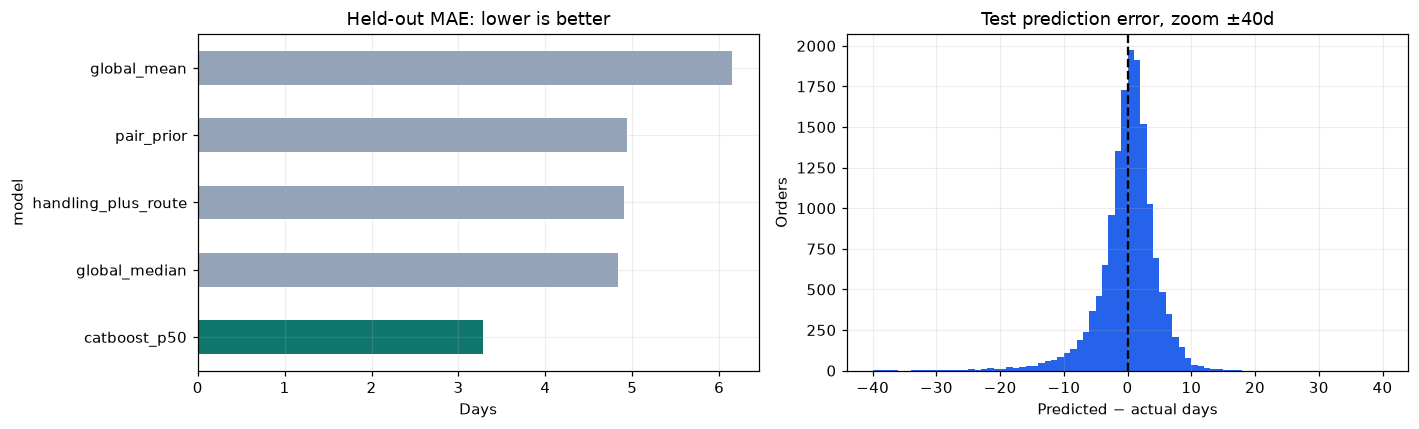

In [9]:
xtest,_ = make_delivery_features(test,BASE_FEATURES,engineered=config['engineered'],use_ids=config['use_ids'])
offset_test = test.pair_delivery_days_smoothed.to_numpy() if config['residual'] else np.zeros(len(test))
test_predictions = baseline_predictions(test,fit)
pred50 = np.maximum(0,final_models['p50'].predict(xtest)+offset_test)
raw90 = np.maximum(0,final_models['p90'].predict(xtest)+offset_test)
pred90 = np.maximum(pred50,raw90)
test_predictions['catboost_p50'] = pred50
results = pd.DataFrame([{'model':name,**metrics(test[TARGET],pred,test)} for name,pred in test_predictions.items()]).sort_values('MAE').reset_index(drop=True)
display(results)
results.to_csv(REPORT / 'test_metrics.csv',index=False)
quantile_metrics = {'p50_empirical_coverage':float((test[TARGET].to_numpy()<=pred50).mean()),
                    'p90_empirical_coverage':float((test[TARGET].to_numpy()<=pred90).mean()),
                    'p90_pinball':float(mean_pinball_loss(test[TARGET],pred90,alpha=.9)),
                    'raw_quantile_crossing_rate':float((raw90<pred50).mean()),
                    'median_p90_minus_p50_days':float(np.median(pred90-pred50))}
display(pd.Series(quantile_metrics,name='value').to_frame())
fig,axes=plt.subplots(1,2,figsize=(13,4))
results.set_index('model').MAE.sort_values().plot.barh(ax=axes[0],color=['#0f766e' if c=='catboost_p50' else '#94a3b8' for c in results.sort_values('MAE').model]);axes[0].set(title='Held-out MAE: lower is better',xlabel='Days')
err = pred50-test[TARGET].to_numpy();axes[1].hist(err,bins=np.linspace(-40,40,81),color='#2563eb');axes[1].axvline(0,color='black',linestyle='--');axes[1].set(title='Test prediction error, zoom ±40d',xlabel='Predicted − actual days',ylabel='Orders')
plt.tight_layout();show_figure('04_test_comparison')

### Бизнес-метрика: среднее опоздание относительно прогноза

Для каждого заказа задаём **штраф = max(фактические дни − прогноз, 0)**. Если доставка произошла раньше прогноза или точно в срок, штраф равен нулю. Если обещали 8 дней, а доставка заняла 11, штраф — 3 дня. Итоговая метрика — средний штраф **по всем заказам**, включая нули.

Дополнительно показываем долю заказов с ненулевым штрафом, среднее опоздание среди опоздавших, MAE и средний обещанный срок. Метрика не штрафует завышение срока: достаточно обещать очень много дней, чтобы получить ноль. Поэтому её нужно рассматривать вместе с длительностью обещания и MAE.

Для сравнения добавлено исходное обещание Olist. Его дата приведена к той же точке отсчёта — подтверждению оплаты. Это диагностическое сравнение готового обещания заказа, а не признак ночной модели. Новая метрика оценивает уже выбранные модели; обучение и подбор по test не меняются.

In [13]:
from marts.delivery_metrics import late_delivery_days, mean_late_delivery_days

# Definition check: early, exactly on time, 3 days late.
assert np.array_equal(late_delivery_days([5, 8, 11], [8, 8, 8]), [0, 0, 3])
assert mean_late_delivery_days([5, 8, 11], [8, 8, 8]) == 1.0
promise_predictions = {
    'catboost_p50': np.asarray(pred50),
    'catboost_p90': np.asarray(pred90),
    'olist_promise': (test.olist_estimate_days - test.approval_hours / 24).to_numpy(),
}
promise_rows = []
y_actual = test[TARGET].to_numpy()
for name, prediction in promise_predictions.items():
    late = late_delivery_days(y_actual, prediction)
    promise_rows.append({
        'model': name,
        'MAE_days': mean_absolute_error(y_actual, prediction),
        'RMSE_days': float(np.sqrt(mean_squared_error(y_actual, prediction))),
        'MedianAE_days': median_absolute_error(y_actual, prediction),
        'Mean_late_days_all_orders': mean_late_delivery_days(y_actual, prediction),
        'Late_order_share': float((late > 0).mean()),
        'On_time_coverage': float((late == 0).mean()),
        'Mean_late_days_among_late': float(late[late > 0].mean()) if (late > 0).any() else 0.0,
        'Mean_promised_days': float(prediction.mean()),
    })
promise_metrics = pd.DataFrame(promise_rows)
display(promise_metrics)
promise_metrics.to_csv(REPORT / 'promise_metrics.csv', index=False)


,model,MAE_days,RMSE_days,MedianAE_days,Mean_late_days_all_orders,Late_order_share,On_time_coverage,Mean_late_days_among_late,Mean_promised_days
0,catboost_p50,3.282139,5.241830,2.230504,1.699244,0.440803,0.559197,3.854883,8.596420
1,catboost_p90,10.057779,11.118408,9.613032,0.270388,0.035801,0.964199,7.552484,18.229771
2,olist_promise,13.158137,15.794413,12.141759,0.306506,0.055742,0.944258,5.498660,21.257893


,group,segment,model,orders,MAE,p90_coverage
0,pair_history_group,1–4 past deliveries,catboost_p50,3252,3.278558,0.962177
1,pair_history_group,1–4 past deliveries,pair_prior,3252,4.969543,0.962177
2,pair_history_group,5+ past deliveries,catboost_p50,3153,2.987494,0.961307
3,pair_history_group,5+ past deliveries,pair_prior,3153,4.441733,0.961307
4,pair_history_group,no history,catboost_p50,8790,3.389153,0.965984
5,pair_history_group,no history,pair_prior,8790,5.101761,0.965984
6,seller_history_group,new seller,catboost_p50,723,3.160793,0.979253
7,seller_history_group,new seller,pair_prior,723,5.127051,0.979253
8,seller_history_group,seller with history,catboost_p50,14472,3.288201,0.963447
9,seller_history_group,seller with history,pair_prior,14472,4.926987,0.963447


,month,orders,catboost_MAE,baseline_MAE,p90_coverage
0,2018-06,5869,3.277279,4.950278,0.967627
1,2018-07,5504,3.463614,5.173581,0.962391
2,2018-08,3822,3.028261,4.573953,0.961538


,importance
days_since_2017,32.021178
month_cos,14.385009
seller_id,5.647058
distance_km,5.504792
log1p_distance_km,5.126102
platform_in_transit,4.612956
platform_orders_7d,3.758258
city_transit_vs_state,2.978502
seller_handling_days_median,2.133162
dow_cos,2.112000


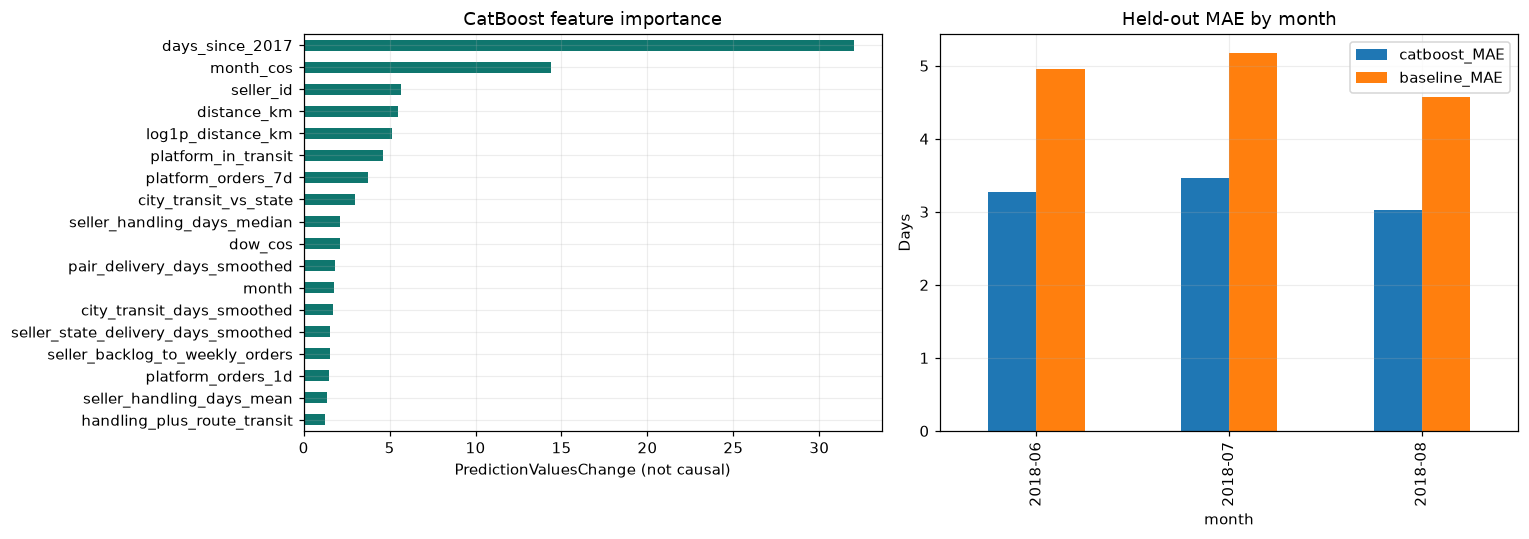

Снижение MAE против pair_prior : 1.6544 дня; day-bootstrap 95% CI: [1.55639604 1.7587345 ]


In [10]:
scored=test[KEYS+['order_id','purchase_ts','label_available_ts',TARGET,'pair_n_delivered','seller_n_delivered','distance_km','customer_state']].copy()
scored['eta_p50_days']=pred50;scored['eta_p90_days']=pred90
scored['late_days_p50']=late_delivery_days(scored[TARGET],pred50)
scored['late_days_p90']=late_delivery_days(scored[TARGET],pred90)
scored['baseline_prediction']=test_predictions[strong_baseline]
scored['pair_history_group']=np.select([test.pair_n_delivered.eq(0),test.pair_n_delivered.lt(5)],['no history','1–4 past deliveries'],default='5+ past deliveries')
scored['seller_history_group']=np.where(test.seller_n_delivered.eq(0),'new seller','seller with history')
segment_rows=[]
for group in ['pair_history_group','seller_history_group']:
    for label,g in scored.groupby(group):
        for name,column in [('catboost_p50','eta_p50_days'),(strong_baseline,'baseline_prediction')]:
            segment_rows.append({'group':group,'segment':label,'model':name,'orders':len(g),
                                 'MAE':mean_absolute_error(g[TARGET],g[column]),
                                 'p90_coverage':float(g[TARGET].le(g.eta_p90_days).mean())})
segments=pd.DataFrame(segment_rows);display(segments);segments.to_csv(REPORT/'segment_metrics.csv',index=False)
monthly_test=[]
for month,g in scored.groupby(scored.forecast_date.dt.to_period('M')):
    monthly_test.append({'month':str(month),'orders':len(g),'catboost_MAE':mean_absolute_error(g[TARGET],g.eta_p50_days),
                         'baseline_MAE':mean_absolute_error(g[TARGET],g.baseline_prediction),'p90_coverage':g[TARGET].le(g.eta_p90_days).mean()})
monthly_test=pd.DataFrame(monthly_test);display(monthly_test);monthly_test.to_csv(REPORT/'test_by_month.csv',index=False)

# Day-block bootstrap preserves within-day dependence. It does not measure uncertainty of refitting the model.
scored['improvement'] = np.abs(scored.baseline_prediction-scored[TARGET])-np.abs(scored.eta_p50_days-scored[TARGET])
daily=scored.groupby('forecast_date').agg(delta=('improvement','sum'),n=('order_id','size'))
rng=np.random.default_rng(SEED);draw=rng.integers(0,len(daily),size=(2000,len(daily)))
boot=daily.delta.to_numpy()[draw].sum(axis=1)/daily.n.to_numpy()[draw].sum(axis=1)
ci=np.quantile(boot,[.025,.975]);print('Снижение MAE против',strong_baseline,':',round(scored.improvement.mean(),4),'дня; day-bootstrap 95% CI:',ci)
importance=pd.Series(final_models['p50'].feature_importances_,index=xfit.columns).sort_values(ascending=False)
display(importance.head(20).rename('importance').to_frame());importance.to_csv(REPORT/'feature_importance.csv',header=['importance'])
fig,axes=plt.subplots(1,2,figsize=(14,5))
importance.head(18).sort_values().plot.barh(ax=axes[0],color='#0f766e');axes[0].set(title='CatBoost feature importance',xlabel='PredictionValuesChange (not causal)')
monthly_test.set_index('month')[['catboost_MAE','baseline_MAE']].plot.bar(ax=axes[1]);axes[1].set(title='Held-out MAE by month',ylabel='Days')
plt.tight_layout();show_figure('05_importance_and_months')

## 8. Сохранение модели и ночной расчёт

Сохраняем native CatBoost-модели, контракт признаков и дату, до которой разрешены обучающие метки. `DeliveryModel.predict()` принимает готовую витрину пары на дату; позднее её можно читать из SQL.

Для Parquet-этапа `LocalPairFeatures` пересчитывает исторические признаки один раз на D и отдаёт полную сетку активных продавцов × городов порциями. Активность: заказ за последние 90 дней; города: заказ за последние 365 дней. Полная сетка не материализуется в памяти.

Ниже выполняется исторический пример на 2 июля 2018 — с моделью, обученной до 1 июня, и событиями только до 2 июля. Проверяем совпадение пересчитанных признаков с обучающей витриной и прогнозы для новых пар. `computed_at_utc` сохраняет фактическое время пересчёта, поэтому это replay, а не поддельная запись о расчёте в 2018 году.

In [11]:
MODEL_VERSION='catboost_pair_v1_asof20180601'
selected_catalog=pd.DataFrame({'feature':list(xfit),'group':['base' if c in BASE_FEATURES else ('id' if c in ['seller_id','city_id'] else 'engineered') for c in xfit],'categorical':[c in cats for c in xfit]})
selected_catalog.to_csv(REPORT/'feature_catalog.csv',index=False)
for name,model in final_models.items():
    model.save_model(str(MODEL_DIR/f'{name}.cbm'))
metadata={'model_version':MODEL_VERSION,'target':TARGET,'grain':KEYS,'fit_as_of':str(FIT_AS_OF.date()),
          'engineered':config['engineered'],'use_ids':config['use_ids'],'residual':config['residual'],
          'base_features':BASE_FEATURES,'features':list(xfit),'categorical_features':cats,
          'p50_iterations':final_models['p50'].tree_count_,'p90_iterations':final_models['p90'].tree_count_,
          'selected_on_validation':best_name,'seed':SEED,'catboost_version':catboost.__version__,
          'source_sha256':store.manifest['source_sha256']}
(MODEL_DIR/'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2)+'\n')
predictor=DeliveryModel(MODEL_DIR)
unique_test=test.drop_duplicates(KEYS)
loaded=predictor.predict(unique_test)
expected=pd.Series(pred50,index=test.index).loc[unique_test.index].to_numpy()
assert np.allclose(loaded.eta_p50_days,expected)
# All orders sharing a pair-day receive the same point and quantile prediction.
assert scored.groupby(KEYS).eta_p50_days.nunique().max()==1
assert scored.groupby(KEYS).eta_p90_days.nunique().max()==1

adapter=LocalPairFeatures(store)
D=pd.Timestamp('2018-07-02')
grid_size=adapter.prepare(D)
pairs_on_day=test.loc[test.forecast_date.eq(D),['seller_id','city_id']].drop_duplicates()
active_sellers,active_cities=adapter.active_universe(D)
# New entities that first appear on D are outside the active nightly grid;
# they can be requested explicitly through prepare(..., seller_ids=..., city_ids=...).
in_grid=pairs_on_day.seller_id.isin(active_sellers)&pairs_on_day.city_id.isin(active_cities)
print('Фактических пар дня в активной сетке:',int(in_grid.sum()),'| вне сетки:',int((~in_grid).sum()))
pairs_on_day=pairs_on_day[in_grid]
replayed=adapter.features(pairs_on_day)
reference=test[test.forecast_date.eq(D)].drop_duplicates(KEYS).set_index(KEYS).sort_index()
actual=replayed.set_index(KEYS).sort_index()
reference=reference.reindex(actual.index)
for c in BASE_FEATURES:
    pd.testing.assert_series_equal(actual[c],reference[c],check_names=False,check_dtype=False,rtol=1e-8,atol=1e-8)
# A genuinely sparse grid batch includes combinations with no previous orders.
batch_features=next(adapter.iter_grid(batch_size=5000))
nightly_sample=predictor.predict(batch_features)
nightly_sample.to_parquet(REPORT/'nightly_sample_2018-07-02.parquet',index=False)
print('Полная сетка на D:',grid_size,'пар; проверена порция:',len(nightly_sample))
print('Пар без истории в порции:',int((~nightly_sample.has_pair_history).sum()))
display(nightly_sample.head(10))
assert nightly_sample[KEYS].duplicated().sum()==0
assert nightly_sample.eta_p90_days.ge(nightly_sample.eta_p50_days).all()
print('Проверки сохранения/загрузки, паро-дня и train/serve parity пройдены.')

# Полный расчёт при необходимости: каждая порция — отдельный Parquet part.
# output=REPORT/'delivery_eta_daily_2018-07-02';output.mkdir(exist_ok=True)
# for part_no,features in enumerate(adapter.iter_grid(batch_size=20000)):
#     predictor.predict(features).to_parquet(output/f'part-{part_no:05d}.parquet',index=False)

,seller_id,city_id,forecast_date,eta_p50_days,eta_p90_days,has_pair_history,model_version,computed_at_utc
0,001cca7ae9ae17fb1caed9dfb1094831,AC|cruzeiro do sul,2018-07-02,9.059717,21.547004,False,catboost_pair_v1_asof20180601,2026-10-28 10:39:01.490847+00:00
1,001cca7ae9ae17fb1caed9dfb1094831,AC|epitaciolandia,2018-07-02,8.757189,21.547004,False,catboost_pair_v1_asof20180601,2026-10-28 10:39:01.490847+00:00
2,001cca7ae9ae17fb1caed9dfb1094831,AC|manoel urbano,2018-07-02,8.744969,21.547004,False,catboost_pair_v1_asof20180601,2026-10-28 10:39:01.490847+00:00
3,001cca7ae9ae17fb1caed9dfb1094831,AC|rio branco,2018-07-02,9.059717,21.709605,False,catboost_pair_v1_asof20180601,2026-10-28 10:39:01.490847+00:00
4,001cca7ae9ae17fb1caed9dfb1094831,AC|senador guiomard,2018-07-02,8.698269,21.547004,False,catboost_pair_v1_asof20180601,2026-10-28 10:39:01.490847+00:00
5,001cca7ae9ae17fb1caed9dfb1094831,AC|xapuri,2018-07-02,8.929966,21.547004,False,catboost_pair_v1_asof20180601,2026-10-28 10:39:01.490847+00:00
6,001cca7ae9ae17fb1caed9dfb1094831,AL|agua branca,2018-07-02,8.587682,20.881037,False,catboost_pair_v1_asof20180601,2026-10-28 10:39:01.490847+00:00
7,001cca7ae9ae17fb1caed9dfb1094831,AL|anadia,2018-07-02,8.578154,20.881037,False,catboost_pair_v1_asof20180601,2026-10-28 10:39:01.490847+00:00
8,001cca7ae9ae17fb1caed9dfb1094831,AL|arapiraca,2018-07-02,8.665441,20.881037,False,catboost_pair_v1_asof20180601,2026-10-28 10:39:01.490847+00:00
9,001cca7ae9ae17fb1caed9dfb1094831,AL|atalaia,2018-07-02,8.568959,20.881037,False,catboost_pair_v1_asof20180601,2026-10-28 10:39:01.490847+00:00


Фактических пар дня в активной сетке: 142 | вне сетки: 8
Полная сетка на D: 6414240 пар; проверена порция: 5000
Пар без истории в порции: 4872
Проверки сохранения/загрузки, паро-дня и train/serve parity пройдены.


## 9. Выводы и ограничения

Числа ниже формируются из завершённого эксперимента. Для среднего срока и осторожного обещания нужны разные выходы: p50 оценивает типичный срок, p90 — верхний квантиль. Данные заканчиваются в 2018 году; качество на текущем трафике потребует свежей истории и нового backtest. Забастовка и другие временные сдвиги могут менять калибровку p90.

Оценка здесь условна на корректную доставку одного продавца. Незавершённые и отменённые заказы, новые продавцы без данных о географии и индивидуальные свойства будущей посылки не покрываются этой моделью. При заказе у нескольких продавцов в проде можно брать максимум прогнозов их пар, но это правило не проверено на отдельной разметке посылок.

Сегменты, перцентили и feature importance — описательные результаты первого эксперимента. Гиперпараметры выбирались по одному временному validation; для устойчивого выбора потребуется rolling backtest.

В этом эксперименте важность календаря и даты особенно высока. Поэтому выигрыш на одном временном тесте не доказывает устойчивость в другом логистическом режиме. Покрытие p90 на validation и test рассматривается отдельно; калибровка по test не проводится.

In [12]:
best_mae=float(results.set_index('model').loc['catboost_p50','MAE'])
base_mae=float(results.set_index('model').loc[strong_baseline,'MAE'])
summary={'model_version':MODEL_VERSION,'selected_boosting':best_name,'selected_baseline':strong_baseline,
         'target':'days from payment approval to customer delivery','grain':KEYS,
         'features':len(xfit.columns),'test_orders':len(test),'test_pair_days':len(test[KEYS].drop_duplicates()),
         'test_from':str(FIT_AS_OF.date()),'test_to_exclusive':str(TEST_END.date()),
         'test_MAE_days':best_mae,'baseline_MAE_days':base_mae,
         'MAE_reduction_pct':100*(1-best_mae/base_mae),
         'MAE_improvement_day_bootstrap_95ci':[float(v) for v in ci],
         'promise_metrics':promise_metrics.to_dict(orient='records'),
         'custom_metric':{'name':'mean_late_delivery_days','formula':'mean(max(actual_days - predicted_days, 0))','denominator':'all test orders'},
         'quantiles':quantile_metrics,'validation':validation_results.fillna('').to_dict(orient='records'),
         'test_metrics':results.to_dict(orient='records'),'checks':[
             'no order-specific model features','pair-day feature invariance','labels available before fit cutoff',
             'test not used for model selection','saved model prediction parity',
             'recomputed daily features match training mart','new pair scoring and ordered quantiles']}
(REPORT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2)+'\n')
scored.to_parquet(REPORT/'test_predictions.parquet',index=False)
print(f"Test MAE: {best_mae:.3f} дня; baseline {strong_baseline}: {base_mae:.3f} дня; снижение {summary['MAE_reduction_pct']:.1f}%")
print(f"p90 покрытие: {quantile_metrics['p90_empirical_coverage']:.1%}")
print('Модели:',MODEL_DIR)
print('Отчёты и прогнозы:',REPORT)

Test MAE: 3.282 дня; baseline pair_prior: 4.937 дня; снижение 33.5%
p90 покрытие: 96.4%
Модели: /Users/sptrent/projects/data/models/delivery_eta
Отчёты и прогнозы: /Users/sptrent/projects/data/reports/delivery_eta
